# ASF and wild boar road collisions in Catalonia

**Question:** after African swine fever (ASF) was confirmed in Catalonia on 28 Nov 2025, did wild boar road collisions drop in the outbreak zone compared with the rest of Catalonia?

**Data:** Mossos d'Esquadra via Transparència Catalunya, dataset `ght6-dqp5`  
API: https://analisi.transparenciacatalunya.cat/resource/ght6-dqp5.json

**Contents:** load and clean the data, data quality checks, monthly collisions for all of Catalonia, then the outbreak zone compared with the rest.

## 1. Load and explore

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
df = pd.read_json("https://analisi.transparenciacatalunya.cat/resource/ght6-dqp5.json?$limit=30000")
df.shape

(29486, 19)

The API returns only 1,000 rows by default, so $limit=30000 loads all 29,486 rows.

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29486 entries, 0 to 29485
Data columns (total 19 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   any_inici_actuacio                29486 non-null  object 
 1   hora_inici_actuacio               29485 non-null  object 
 2   data_inici_actuacio               29485 non-null  object 
 3   provincia_actuacio                29485 non-null  object 
 4   regio_policial_actuacio           29485 non-null  object 
 5   comarca_actuacio                  29485 non-null  object 
 6   codi_comarca                      29485 non-null  float64
 7   municipi_actuacio                 29485 non-null  object 
 8   codi_municipi                     29485 non-null  float64
 9   via_urbana_interurbana            29485 non-null  object 
 10  via_actuacio                      29485 non-null  object 
 11  numero_punt_quilometric_actuacio  29485 non-null  float64
 12  esta

The injury columns (ferits_lleus, ferits_greus, morts) count people, not animals. A blank means 0.

In [9]:
df.head()

,any_inici_actuacio,hora_inici_actuacio,data_inici_actuacio,provincia_actuacio,regio_policial_actuacio,comarca_actuacio,codi_comarca,municipi_actuacio,codi_municipi,via_urbana_interurbana,via_actuacio,numero_punt_quilometric_actuacio,estat_accident,valoracio_accident,animal_accident,ilesos,ferits_lleus,morts,ferits_greus
0,2025,00:00:04,2025-05-04T00:00:00.000,Barcelona,RP Metropolitana Nord,Vallès Oriental,41.0,"Garriga, la",80885.0,Interurbana,C-17,29.5,Accident il·lès,Es desconeix si es realitzava una acció de caç...,Ungulat (porc senglar),2.0,NaN,NaN,NaN
1,2025,00:00:13,2025-07-02T00:00:00.000,Tarragona,RP Terres de l'Ebre,Montsià,22.0,Alcanar,430043.0,Interurbana,N-340,1059.0,Accident il·lès,Es desconeix si es realitzava una acció de caç...,Ungulat (porc senglar),1.0,NaN,NaN,NaN
2,2025,00:00:24,2025-06-26T00:00:00.000,Barcelona,RP Metropolitana Nord,Vallès Occidental,40.0,Sabadell,81878.0,Interurbana,NA,0.5,Accident il·lès,No a conseqüència de l'acció de caça. Via no s...,Ungulat (porc senglar),1.0,NaN,NaN,NaN
3,2025,00:00:26,2025-11-24T00:00:00.000,Girona,RP Girona,Selva,34.0,Santa Coloma de Farners,171805.0,Interurbana,C-152,1.3,Accident il·lès,Es desconeix si es realitzava una acció de caç...,Ungulat (porc senglar),1.0,NaN,NaN,NaN
4,2025,00:00:28,2025-08-08T00:00:00.000,Girona,RP Girona,Alt Empordà,2.0,Navata,171117.0,Interurbana,N-260,46.7,Accident il·lès,No a conseqüència de l'acció de caça. Via no s...,Ungulat (porc senglar),1.0,NaN,NaN,NaN


In [10]:
df["any_inici_actuacio"].value_counts()

any_inici_actuacio
2022     6114
2025     6003
2024     5822
2023     5742
2026     2943
2021     2861
Total       1
Name: count, dtype: int64

In [11]:
df["animal_accident"].value_counts()

animal_accident
Ungulat (porc senglar)                     19038
Cèrvids (cabirol, isard, cérvol, daina)     7669
Domèstic (gos,gat)                          1342
Salvatge (guineu, teixó, gineta)             795
No identificat                               315
Boví (vaca, ovella)                           83
Altres                                        82
Equí (cavall, ruc)                            69
Altres (voltor, àliga, rapinyaires)           66
Aus (voltor, àliga, rapinyaires)              26
Name: count, dtype: int64

The exact label for wild boar is Ungulat (porc senglar). Some bird labels are duplicated.

In [12]:
df = df[df["any_inici_actuacio"] != "Total"]
df.shape

(29485, 19)

The year column had a “Total” summary row. It’s removed, which leaves 29,485 rows.

In [13]:
df["any_inici_actuacio"] = df["any_inici_actuacio"].astype(int)
df.dtypes

any_inici_actuacio                    int64
hora_inici_actuacio                  object
data_inici_actuacio                  object
provincia_actuacio                   object
regio_policial_actuacio              object
comarca_actuacio                     object
codi_comarca                        float64
municipi_actuacio                    object
codi_municipi                       float64
via_urbana_interurbana               object
via_actuacio                         object
numero_punt_quilometric_actuacio    float64
estat_accident                       object
valoracio_accident                   object
animal_accident                      object
ilesos                              float64
ferits_lleus                        float64
morts                               float64
ferits_greus                        float64
dtype: object

In [14]:
boar = df[df["animal_accident"] == "Ungulat (porc senglar)"]
boar.shape

(19038, 19)

In [15]:
boar["any_inici_actuacio"].value_counts().sort_index()

any_inici_actuacio
2021    2120
2022    4288
2023    3697
2024    3638
2025    3829
2026    1466
Name: count, dtype: int64

2026 stops in June, and 2021 looks low (checked below).

In [16]:
df["data_inici_actuacio"] = pd.to_datetime(df["data_inici_actuacio"])
df.dtypes

any_inici_actuacio                           int64
hora_inici_actuacio                         object
data_inici_actuacio                 datetime64[ns]
provincia_actuacio                          object
regio_policial_actuacio                     object
comarca_actuacio                            object
codi_comarca                               float64
municipi_actuacio                           object
codi_municipi                              float64
via_urbana_interurbana                      object
via_actuacio                                object
numero_punt_quilometric_actuacio           float64
estat_accident                              object
valoracio_accident                          object
animal_accident                             object
ilesos                                     float64
ferits_lleus                               float64
morts                                      float64
ferits_greus                               float64
dtype: object

In [17]:
df["mes"] = df["data_inici_actuacio"].dt.month
df[["data_inici_actuacio", "mes"]].head()

,data_inici_actuacio,mes
0,2025-05-04,5
1,2025-07-02,7
2,2025-06-26,6
3,2025-11-24,11
4,2025-08-08,8


In [18]:
boar = df[df["animal_accident"] == "Ungulat (porc senglar)"]
boar_2021 = boar[boar["any_inici_actuacio"] == 2021]
boar_2021["mes"].value_counts().sort_index()

mes
1      51
2      45
3      32
4      25
5      31
6      21
7      34
8      55
9     306
10    494
11    512
12    514
Name: count, dtype: int64

In [19]:
boar_2022 = boar[boar["any_inici_actuacio"] == 2022]
boar_2022["mes"].value_counts().sort_index()

mes
1     370
2     322
3     245
4     229
5     205
6     199
7     229
8     265
9     314
10    562
11    777
12    571
Name: count, dtype: int64

### 1.1 Year 2021 is not comparable before September
From January to August 2021 there are only 21 to 55 boar collisions a month, then 306 in September and around 500 a month to December. January to August 2022 has 199 to 370 a month, and September matches in both years (306 vs 314), so the jump is likely a change in recording from September 2021, not fewer collisions. Monthly analysis starts in September 2021; yearly totals use 2022 to 2025 only.

## 2. Monthly boar collisions, all of Catalonia

In [20]:
monthly = (
    boar.set_index("data_inici_actuacio")
        .resample("MS")
        .size()
)
monthly = monthly[monthly.index >= "2021-09-01"]

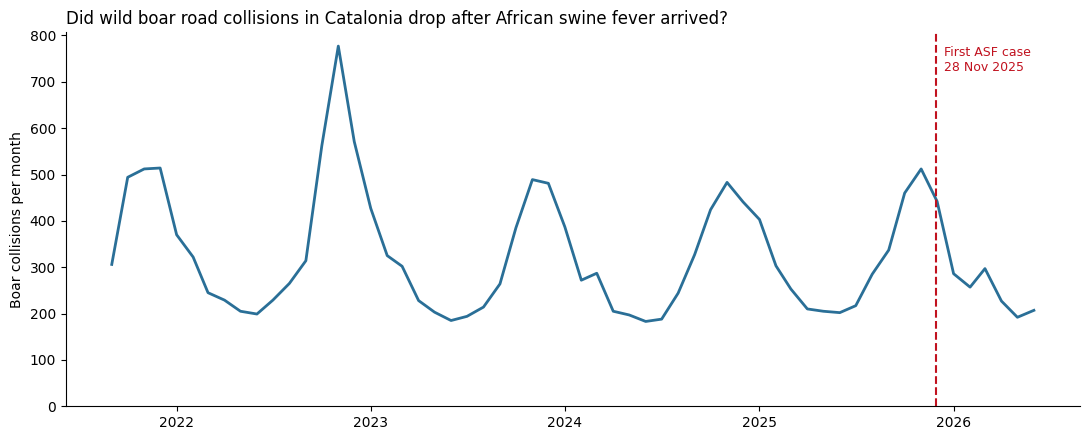

In [21]:
fig, ax = plt.subplots(figsize=(11, 4.5))

ax.plot(monthly.index, monthly.values, color="#2a6f97", linewidth=2)
ax.axvline(pd.Timestamp("2025-11-28"), color="#c1121f", linestyle="--", linewidth=1.5)
ax.text(pd.Timestamp("2025-11-28"), monthly.max(), "  First ASF case\n  28 Nov 2025",
        color="#c1121f", va="top", fontsize=9)
ax.set_title("Did wild boar road collisions in Catalonia drop after African swine fever arrived?",
             loc="left", fontsize=12)
ax.set_ylabel("Boar collisions per month")
ax.set_ylim(bottom=0)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 3. Outbreak zone vs rest of Catalonia

**Zone definition:** the 91 municipalities of the official infected and surveillance zone (`zone.csv`, checked against the EU zone list per comarca), split into **core** (12 municipalities, 6 km infected radius) and **ring** (the other 79). Everything else is **rest of Catalonia**. "After" means from 28 Nov 2025.

### 3.1 Join the zone list

In [22]:
zone = pd.read_csv("zone.csv")
zone["group"] = zone["zone"].map({"core_6km": "core", "ring_20km": "ring", "eu_extension": "ring"})
zone_codes = zone.dropna(subset=["codi_municipi"])[["codi_municipi", "group"]]

boar = boar.merge(zone_codes, on="codi_municipi", how="left")
boar["group"] = boar["group"].fillna("rest")
boar["group"].value_counts()

group
rest    17134
ring     1372
core      532
Name: count, dtype: int64

### 3.2 Check: share of boar collisions by group, normal years (2022 to 2025)

In [24]:
normal = boar[boar["any_inici_actuacio"].between(2022, 2025)]
share = pd.crosstab(normal["any_inici_actuacio"], normal["group"], normalize="index").mul(100).round(1)
share[["core", "ring", "rest"]]

group,core,ring,rest
any_inici_actuacio,,,
2022,2.8,7.2,90.1
2023,2.4,7.1,90.5
2024,3.0,7.0,90.0
2025,3.4,8.1,88.5


In [25]:
counts = pd.crosstab(boar["any_inici_actuacio"], boar["group"])
counts[["core", "ring", "rest"]]

group,core,ring,rest
any_inici_actuacio,,,
2021,55,129,1936
2022,119,307,3862
2023,90,263,3344
2024,108,256,3274
2025,131,310,3388
2026,29,107,1330


### 3.3 January to June: 2026 vs normal years

The data ends on 30 June 2026, so the fair comparison is the same six months in each year.

In [26]:
h1 = boar[boar["mes"] <= 6]
h1_counts = pd.crosstab(h1["any_inici_actuacio"], h1["group"]).loc[2022:2026, ["core", "ring", "rest"]]
h1_counts

group,core,ring,rest
any_inici_actuacio,,,
2022,46,108,1416
2023,34,131,1505
2024,54,97,1380
2025,52,139,1385
2026,29,107,1330


### 3.4 Change against normal years

In [27]:
normal_avg = h1_counts.loc[2022:2025].mean()
change = (h1_counts.loc[2026] - normal_avg) / normal_avg * 100

summary = pd.DataFrame({
    "normal avg 2022 to 2025": normal_avg.round(0),
    "2026": h1_counts.loc[2026],
    "change %": change.round(0),
})
summary

,normal avg 2022 to 2025,2026,change %
group,,,
core,46.0,29,-38.0
ring,119.0,107,-10.0
rest,1422.0,1330,-6.0


### 3.5 Finding

- **Comparison:** January to June 2026 (the only 2026 months in the data) against the same months in the normal years 2022 to 2025.
- **Result:** wild boar collisions fell by 38% in the core, 10% in the ring and 6% in the rest of Catalonia.
- **Interpretation:** the drop is largest where culling and fencing were most intense, and smallest outside the zone. The rest of Catalonia also fell, so the part of the core's drop that could be linked to ASF is the difference: about 32 percentage points.
- **Limits:** the core numbers are small (29 collisions in 2026 against about 46 in a normal year), so the pattern is consistent with an effect but doesn't prove one. The data also can't separate fewer boar from fewer people driving in the area after Collserola was closed in March 2026.

### 3.6 Chart: change by zone

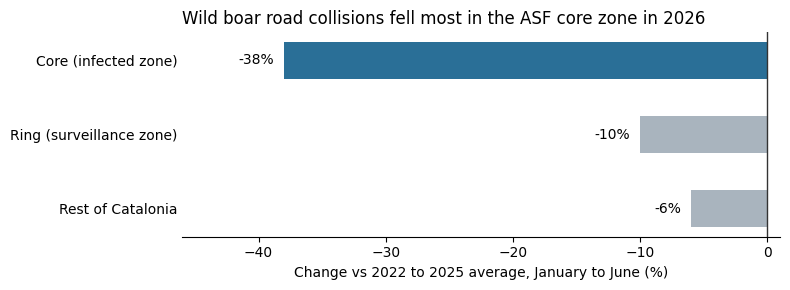

In [28]:
order = ["core", "ring", "rest"]
labels = ["Core (infected zone)", "Ring (surveillance zone)", "Rest of Catalonia"]
vals = summary.loc[order, "change %"]

fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.barh(labels, vals, color=["#2a6f97", "#a9b4be", "#a9b4be"], height=0.5)
ax.invert_yaxis()
ax.axvline(0, color="#333333", linewidth=1)
for bar, v in zip(bars, vals):
    ax.text(v - 0.8, bar.get_y() + bar.get_height() / 2, f"{v:.0f}%", va="center", ha="right", fontsize=10)
ax.set_xlim(vals.min() - 8, 1)
ax.set_xlabel("Change vs 2022 to 2025 average, January to June (%)")
ax.set_title("Wild boar road collisions fell most in the ASF core zone in 2026", loc="left", fontsize=12)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.savefig("zone_change_jan_jun.png", dpi=150)